## 1. Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path


## 2. Load the CSV dataset

In [2]:
data_path = Path("wine_binary_dataset.csv")
if not data_path.exists():
    raise FileNotFoundError("Put wine_binary_dataset.csv in the same folder as this notebook.")

df = pd.read_csv(data_path)
display(df.head())
print("Dataset shape:", df.shape)
print("\nClass counts:")
print(df["class"].value_counts().sort_index())
print("\nMissing values:")
print(df.isnull().sum())


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280_od315,proline,class,cultivar
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0,class_0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0,class_0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0,class_0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0,class_0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0,class_0


Dataset shape: (130, 15)

Class counts:
class
0    59
1    71
Name: count, dtype: int64

Missing values:
alcohol                 0
malic_acid              0
ash                     0
alcalinity_of_ash       0
magnesium               0
total_phenols           0
flavanoids              0
nonflavanoid_phenols    0
proanthocyanins         0
color_intensity         0
hue                     0
od280_od315             0
proline                 0
class                   0
cultivar                0
dtype: int64


## 3. Preprocess the data

In [3]:
feature_columns = [
    "alcohol", "malic_acid", "ash", "alcalinity_of_ash", "magnesium",
    "total_phenols", "flavanoids", "nonflavanoid_phenols", "proanthocyanins",
    "color_intensity", "hue", "od280_od315", "proline"
]
X = df[feature_columns].to_numpy(dtype=float)
y = df["class"].to_numpy(dtype=int)


for j in range(X.shape[1]):
    median = np.nanmedian(X[:, j])
    X[np.isnan(X[:, j]), j] = median

print("Samples:", len(X))
print("Features:", X.shape[1])
print("Labels:", np.unique(y))


Samples: 130
Features: 13
Labels: [0 1]


## 4. Stratified 80/20 train-test split

In [4]:
rng = np.random.default_rng(42)
train_indices, test_indices = [], []

for label in (0, 1):
    indices = np.where(y == label)[0]
    rng.shuffle(indices)
    n_test = int(round(0.20 * len(indices)))
    test_indices.extend(indices[:n_test])
    train_indices.extend(indices[n_test:])

train_indices = np.array(train_indices)
test_indices = np.array(test_indices)
rng.shuffle(train_indices)
rng.shuffle(test_indices)

X_train, X_test = X[train_indices], X[test_indices]
y_train, y_test = y[train_indices], y[test_indices]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 104
Testing samples: 26


## 5. Standardize features

In [5]:

mean = X_train.mean(axis=0)
std = X_train.std(axis=0)
std[std == 0] = 1.0

X_train = (X_train - mean) / std
X_test = (X_test - mean) / std


## 6. Single-Layer Perceptron implemented from scratch

In [6]:
class SingleLayerPerceptron:
    def __init__(self, learning_rate=0.01, epochs=100, seed=42):
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.seed = seed
        self.weights = None
        self.bias = 0.0

    @staticmethod
    def activation(z):
        return (z >= 0).astype(int)

    def predict(self, X):
        return self.activation(X @ self.weights + self.bias)

    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.weights = np.zeros(n_features, dtype=float)
        self.bias = 0.0
        rng = np.random.default_rng(self.seed)

        for epoch in range(self.epochs):
            for i in rng.permutation(n_samples):
                z = np.dot(X[i], self.weights) + self.bias
                prediction = int(z >= 0)
                error = y[i] - prediction

                # Perceptron learning rule.
                self.weights += self.learning_rate * error * X[i]
                self.bias += self.learning_rate * error
        return self


## 7. Train and test the model

In [7]:
model = SingleLayerPerceptron(learning_rate=0.01, epochs=100, seed=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print("Training completed.")


Training completed.


## 8. Evaluate model performance

In [8]:
# Positive class is cultivar class 1.
TP = int(np.sum((y_test == 1) & (y_pred == 1)))
TN = int(np.sum((y_test == 0) & (y_pred == 0)))
FP = int(np.sum((y_test == 0) & (y_pred == 1)))
FN = int(np.sum((y_test == 1) & (y_pred == 0)))

accuracy = (TP + TN) / len(y_test)
precision = TP / (TP + FP) if TP + FP else 0.0
recall = TP / (TP + FN) if TP + FN else 0.0
f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0

print("========== SINGLE-LAYER PERCEPTRON RESULTS ==========")
print(f"Accuracy : {accuracy * 100:.2f}%")
print(f"Precision: {precision * 100:.2f}%")
print(f"Recall   : {recall * 100:.2f}%")
print(f"F1-score : {f1 * 100:.2f}%")

confusion = np.array([[TN, FP], [FN, TP]])
print("\nConfusion matrix (rows=actual, columns=predicted):")
print(confusion)


========== SINGLE-LAYER PERCEPTRON RESULTS ==========
Accuracy : 100.00%
Precision: 100.00%
Recall   : 100.00%
F1-score : 100.00%

Confusion matrix (rows=actual, columns=predicted):
[[12  0]
 [ 0 14]]


## 9. Plot the confusion matrix

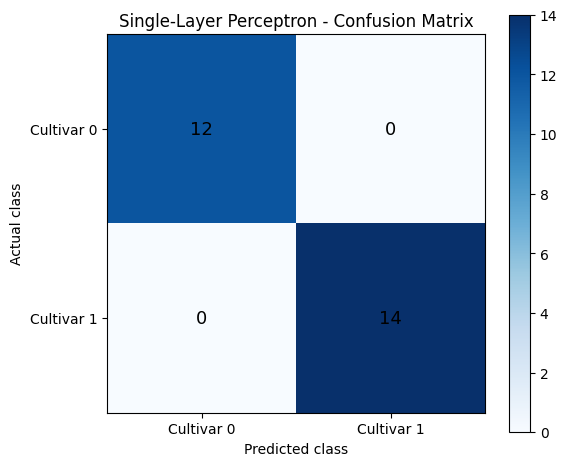

In [9]:
plt.figure(figsize=(6, 5))
plt.imshow(confusion, cmap="Blues")
plt.title("Single-Layer Perceptron - Confusion Matrix")
plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.xticks([0, 1], ["Cultivar 0", "Cultivar 1"])
plt.yticks([0, 1], ["Cultivar 0", "Cultivar 1"])

for i in range(2):
    for j in range(2):
        plt.text(j, i, str(confusion[i, j]),
                 ha="center", va="center", fontsize=13)

plt.colorbar()
plt.tight_layout()
plt.savefig("wine_confusion_matrix.png", dpi=150)
plt.show()
